# Taller 05: Clustering DBSCAN

**Inteligencia Artificial - ELP 8012 - Universidad del Norte**
**Profesor:** Eduardo Zurek, Ph.D.

En este taller se implementa el algoritmo de clustering **DBSCAN** aplicado a un conjunto de datos sintéticos en dos dimensiones. A diferencia de generar los grupos directamente desde coordenadas arbitrarias, en este notebook los grupos amorfos se generan **a partir de una figura dibujada a mano** (`img.png`), tal como lo pide el enunciado del taller.

La figura contiene múltiples trazos (letras, garabatos, lazos y líneas) que se usan como base geométrica: cada trazo conectado de la imagen se convierte en un grupo amorfo, y a partir de sus píxeles se generan los puntos sintéticos con ruido gaussiano. Esto garantiza que los grupos tengan formas irregulares y no convexas, que es justamente el escenario donde DBSCAN es más útil que algoritmos como K-Means.

**Contenido:**
1. Importación de librerías
2. Carga y binarización de la figura
3. Detección de los grupos (trazos) de la figura
4. Generación de los datos sintéticos a partir de los grupos detectados
5. Generación de outliers distribuidos uniformemente
6. Análisis exploratorio con gráficos de k-distancia
7. Implementación de DBSCAN desde cero
8. Evaluación del clustering (Silhouette Score y Adjusted Rand Index)
9. Conclusiones


## 1. Importación de librerías

Se utilizan `NumPy` para el manejo numérico, `Matplotlib` para las visualizaciones, `Pillow` (`PIL`) para leer la imagen, `SciPy` (`ndimage`) para detectar los trazos conectados de la figura, y `scikit-learn` únicamente como apoyo para el análisis de k-distancia (`NearestNeighbors`) y para el cálculo de las métricas de evaluación (`silhouette_score`, `adjusted_rand_score`). El algoritmo DBSCAN en sí se implementa desde cero más adelante.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from scipy import ndimage

from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score, adjusted_rand_score

np.random.seed(42)

## 2. Carga y binarización de la figura

La figura inicial (`img.png`) fue creada a mano y contiene más de 20 trazos independientes (letras, lazos, líneas y garabatos) que sirven como base para los grupos amorfos que pide el taller.

Primero se carga la imagen en escala de grises y se binariza: los píxeles oscuros (la tinta del trazo) se marcan como `True`, y el fondo blanco como `False`.

Dimensiones de la imagen: (846, 1653)


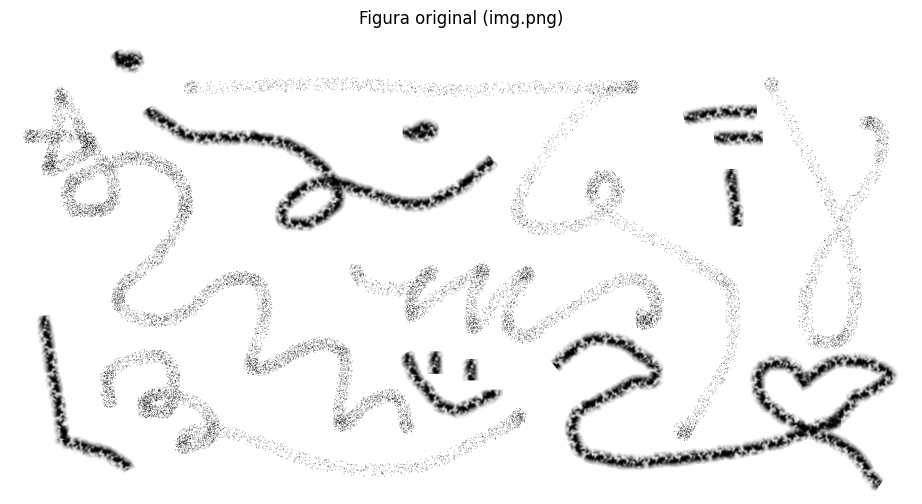

In [2]:
ruta_imagen = "img.png"

imagen = Image.open(ruta_imagen).convert("L")
imagen_array = np.array(imagen)

print("Dimensiones de la imagen:", imagen_array.shape)

plt.figure(figsize=(12, 6))
plt.imshow(imagen_array, cmap="gray")
plt.title("Figura original (img.png)")
plt.axis("off")
plt.show()

Número de píxeles de tinta: 65980


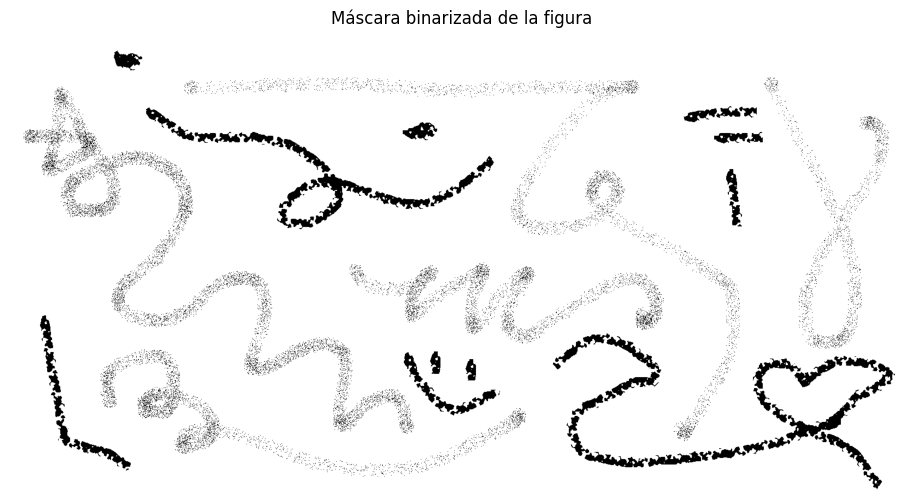

In [3]:
# Umbral de binarización: un pixel se considera "tinta" si es suficientemente oscuro
umbral_binarizacion = 128

mascara_tinta = imagen_array < umbral_binarizacion

print("Número de píxeles de tinta:", mascara_tinta.sum())

plt.figure(figsize=(12, 6))
plt.imshow(mascara_tinta, cmap="gray_r")
plt.title("Máscara binarizada de la figura")
plt.axis("off")
plt.show()

## 3. Detección de los grupos (trazos) de la figura

La imagen tiene ruido tipo "grano" alrededor de los trazos (producto del dibujo/escaneo). Para identificar los trazos reales como componentes conectadas se aplica una **dilatación morfológica leve**, que une los píxeles cercanos de un mismo trazo sin fusionar trazos distintos. Sobre la máscara dilatada se etiquetan las componentes conectadas con `scipy.ndimage.label`.

Luego se descartan las componentes demasiado pequeñas (motas de ruido aisladas) contando, para cada componente, cuántos píxeles de la máscara **original** (sin dilatar) contiene. Esto nos deja con los grupos reales de la figura.

In [4]:
estructura_dilatacion = np.ones((5, 5))
mascara_dilatada = ndimage.binary_dilation(mascara_tinta, structure=estructura_dilatacion)

etiquetas_componentes, num_componentes = ndimage.label(
    mascara_dilatada,
    structure=np.ones((3, 3))
)

print("Componentes encontradas (antes de filtrar ruido):", num_componentes)

# Tamaño real (en la máscara original) de cada componente
tamanos = ndimage.sum(
    mascara_tinta,
    etiquetas_componentes,
    range(1, num_componentes + 1)
)

tamano_minimo = 60
etiquetas_validas = [i + 1 for i, s in enumerate(tamanos) if s > tamano_minimo]

print("Número de grupos amorfos detectados en la figura:", len(etiquetas_validas))

Componentes encontradas (antes de filtrar ruido): 110
Número de grupos amorfos detectados en la figura: 28


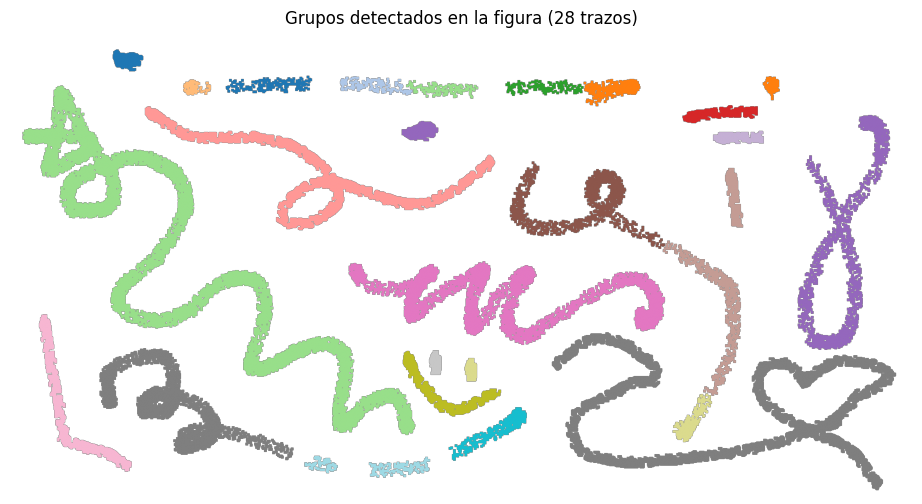

In [5]:
# Visualizar las componentes detectadas con colores distintos
mapa_visual = np.zeros_like(etiquetas_componentes)

for nuevo_id, lbl in enumerate(etiquetas_validas, start=1):
    mapa_visual[etiquetas_componentes == lbl] = nuevo_id

plt.figure(figsize=(12, 6))
plt.imshow(np.ma.masked_where(mapa_visual == 0, mapa_visual), cmap="tab20")
plt.title(f"Grupos detectados en la figura ({len(etiquetas_validas)} trazos)")
plt.axis("off")
plt.show()

### Verificación del requisito de al menos 20 grupos

El enunciado exige que la figura contenga **al menos 20 grupos**. Con el umbral y la dilatación seleccionados se detectaron los grupos suficientes, como se confirma a continuación.

In [6]:
assert len(etiquetas_validas) >= 20, "La figura debe contener al menos 20 grupos"
print(f"Requisito cumplido: {len(etiquetas_validas)} grupos amorfos (>= 20)")

Requisito cumplido: 28 grupos amorfos (>= 20)


## 4. Generación de los datos sintéticos a partir de la figura

Para cada grupo (trazo) detectado se extraen las coordenadas de sus píxeles de tinta en la máscara original. A partir de esas coordenadas se generan los puntos sintéticos:

1. Se reescalan las coordenadas de píxeles de imagen a un rango numérico más manejable (se divide entre 12).
2. Se invierte el eje Y para que la figura se vea en la orientación natural (en la imagen el eje Y crece hacia abajo).
3. Para cada grupo se toman `puntos_por_grupo` muestras aleatorias (con reemplazo) de los píxeles del trazo, y se les agrega ruido gaussiano pequeño (`jitter`). Esto produce una nube de puntos que sigue la forma exacta del trazo dibujado a mano, generando así grupos con formas irregulares (amorfas) y no convexas.

De esta manera, los datos sintéticos no provienen de una fórmula geométrica arbitraria, sino directamente de la figura creada por nosotros.

In [7]:
puntos_por_grupo = 180
jitter = 0.08
escala = 12.0

filas_tinta, columnas_tinta = np.where(mascara_tinta)
etiqueta_por_pixel = etiquetas_componentes[filas_tinta, columnas_tinta]

lista_puntos = []
lista_etiquetas_reales = []

for id_grupo, lbl in enumerate(etiquetas_validas):

    seleccion = etiqueta_por_pixel == lbl

    coordenadas_grupo = np.column_stack([
        columnas_tinta[seleccion].astype(float),
        -filas_tinta[seleccion].astype(float)
    ]) / escala

    indices_muestra = np.random.choice(
        len(coordenadas_grupo),
        size=puntos_por_grupo,
        replace=True
    )

    grupo = coordenadas_grupo[indices_muestra] + np.random.normal(
        0, jitter, size=(puntos_por_grupo, 2)
    )

    lista_puntos.append(grupo)
    lista_etiquetas_reales.extend([id_grupo] * puntos_por_grupo)

puntos = np.vstack(lista_puntos)
etiquetas_reales = np.array(lista_etiquetas_reales)

print("Número total de puntos generados:", len(puntos))
print("Número de grupos:", len(etiquetas_validas))

Número total de puntos generados: 5040
Número de grupos: 28


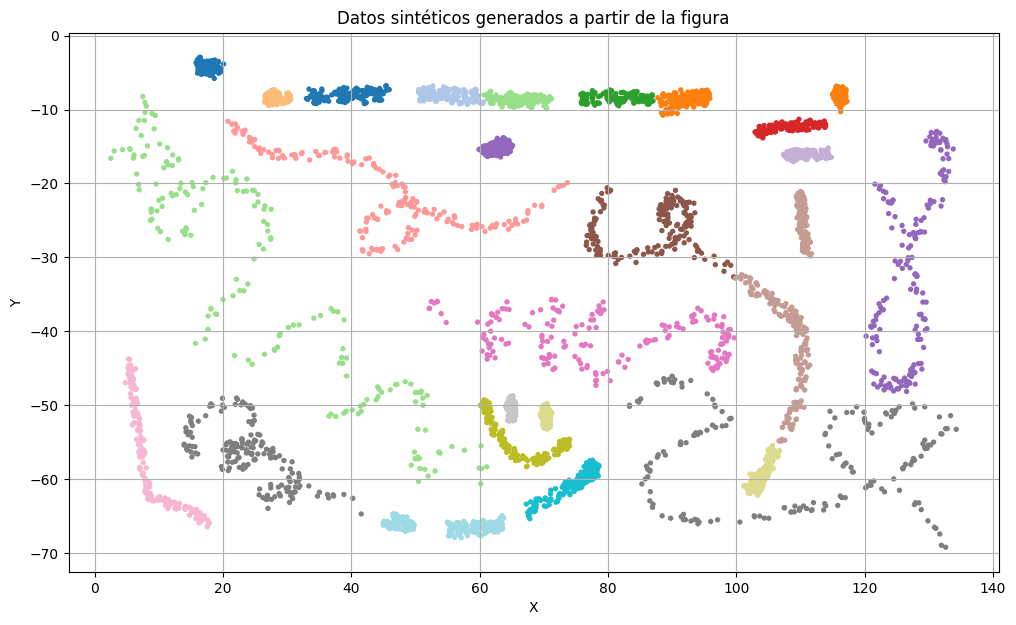

In [8]:
plt.figure(figsize=(12, 7))

plt.scatter(
    puntos[:, 0],
    puntos[:, 1],
    c=etiquetas_reales,
    cmap="tab20",
    s=8
)

plt.title("Datos sintéticos generados a partir de la figura")
plt.xlabel("X")
plt.ylabel("Y")
plt.grid(True)
plt.show()

## 5. Generación de outliers

Siguiendo el enunciado, además de los grupos se generan **datos atípicos (outliers) distribuidos uniformemente** dentro del área que ocupa la figura (con un pequeño margen).

In [9]:
margen = 3.0

x_min, x_max = puntos[:, 0].min() - margen, puntos[:, 0].max() + margen
y_min, y_max = puntos[:, 1].min() - margen, puntos[:, 1].max() + margen

num_outliers = int(0.08 * len(puntos))

outliers = np.column_stack([
    np.random.uniform(x_min, x_max, num_outliers),
    np.random.uniform(y_min, y_max, num_outliers)
])

print("Número de outliers:", len(outliers))

Número de outliers: 403


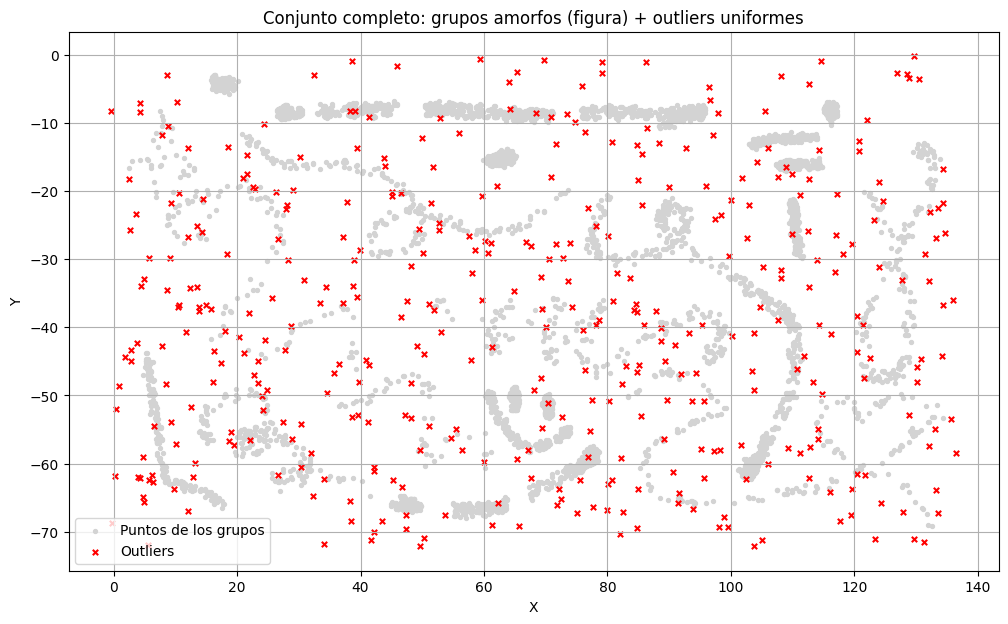

In [10]:
plt.figure(figsize=(12, 7))

plt.scatter(puntos[:, 0], puntos[:, 1], s=8, c="lightgray", label="Puntos de los grupos")
plt.scatter(outliers[:, 0], outliers[:, 1], s=15, marker="x", c="red", label="Outliers")

plt.title("Conjunto completo: grupos amorfos (figura) + outliers uniformes")
plt.xlabel("X")
plt.ylabel("Y")
plt.legend()
plt.grid(True)
plt.show()

In [11]:
datos = np.vstack([puntos, outliers])

etiquetas_referencia = np.concatenate([
    etiquetas_reales,
    np.full(num_outliers, -1)
])

print("Número total de datos:", len(datos))
print("Número de etiquetas de referencia:", len(etiquetas_referencia))

Número total de datos: 5443
Número de etiquetas de referencia: 5443


## 6. Análisis exploratorio: gráficos de k-distancia

Para encontrar valores razonables de **ε (eps)** y **MinPts** se realiza un análisis de k-distancia: para cada punto se calcula la distancia a su k-ésimo vecino más cercano, y se ordenan esas distancias de menor a mayor. El "codo" de la curva resultante sugiere un buen valor de ε para el MinPts analizado.

Se prueban varios valores de k para no basar la decisión en un solo gráfico.

In [12]:
valores_k = [6, 8, 10, 12, 15]

resultados_kdistancia = {}

for k in valores_k:
    vecinos = NearestNeighbors(n_neighbors=k + 1)
    vecinos.fit(datos)

    distancias, _ = vecinos.kneighbors(datos)
    distancias_k = np.sort(distancias[:, -1])

    resultados_kdistancia[k] = distancias_k

print("Análisis de k-distancia realizado para k =", valores_k)

Análisis de k-distancia realizado para k = [6, 8, 10, 12, 15]


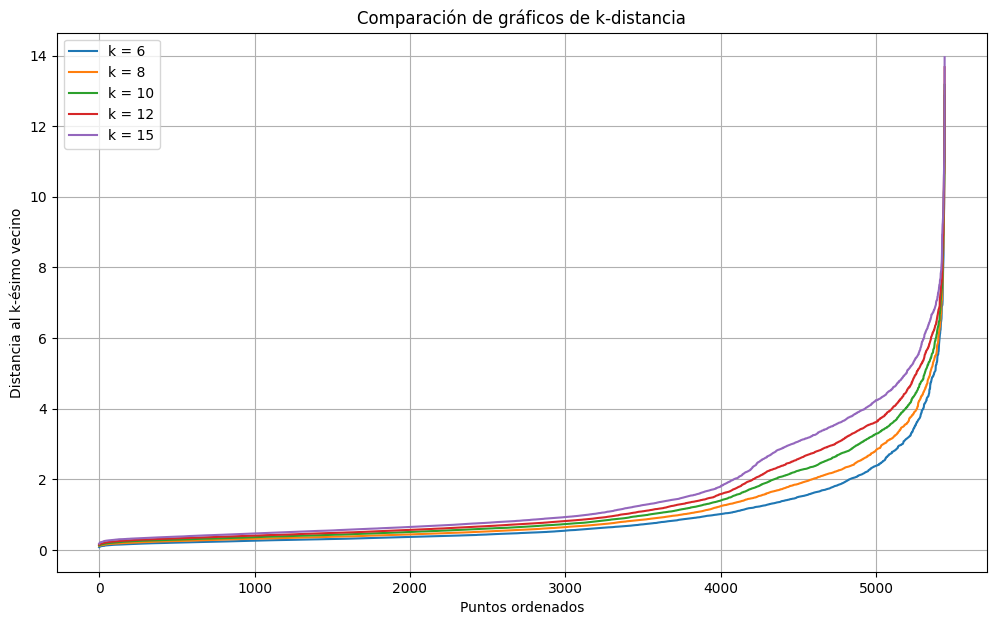

In [13]:
plt.figure(figsize=(12, 7))

for k in valores_k:
    plt.plot(resultados_kdistancia[k], label=f"k = {k}")

plt.title("Comparación de gráficos de k-distancia")
plt.xlabel("Puntos ordenados")
plt.ylabel("Distancia al k-ésimo vecino")
plt.legend()
plt.grid(True)
plt.show()

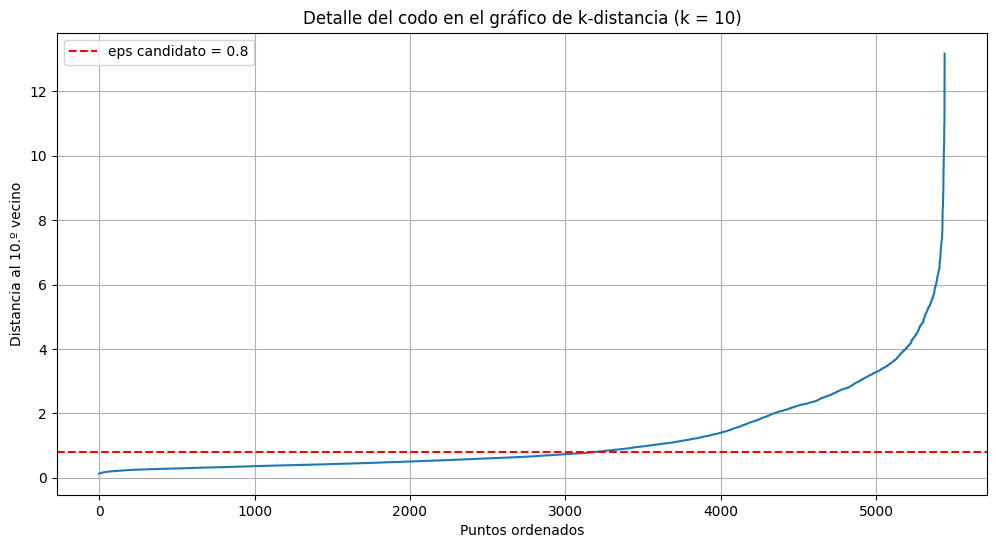

In [14]:
# Zoom en la región del codo para k = 10 (MinPts candidato)
k_foco = 10
distancias_k = resultados_kdistancia[k_foco]

plt.figure(figsize=(12, 6))
plt.plot(distancias_k)
plt.axhline(0.8, color="red", linestyle="--", label="eps candidato = 0.8")

plt.title(f"Detalle del codo en el gráfico de k-distancia (k = {k_foco})")
plt.xlabel("Puntos ordenados")
plt.ylabel(f"Distancia al {k_foco}.º vecino")
plt.legend()
plt.grid(True)
plt.show()

**Interpretación:** para k = 10 el codo de la curva se ubica alrededor de una distancia de **0.7 - 0.9**. Como los grupos generados a partir de la figura son trazos delgados y curvos (no manchas compactas), la densidad local varía más que en un conjunto de datos con clusters convexos, por lo que se exploran varios valores de ε alrededor del codo junto con distintos valores de MinPts antes de fijar la configuración definitiva.

## 7. Implementación del algoritmo DBSCAN desde cero

Se implementa DBSCAN utilizando la distancia euclidiana para determinar los vecinos de cada punto. El algoritmo utiliza dos parámetros:

- **ε (eps):** radio de búsqueda de vecinos.
- **MinPts:** número mínimo de puntos necesarios para considerar que un punto es un punto núcleo (región densa).

Los puntos que no logran asociarse a ningún cluster se etiquetan como ruido (`-1`).

In [15]:
def obtener_vecinos(datos, punto, eps):
    """
    Obtiene los índices de los puntos que se encuentran
    a una distancia menor o igual a eps del punto dado.
    """
    distancias = np.linalg.norm(datos - datos[punto], axis=1)
    vecinos = np.where(distancias <= eps)[0]
    return vecinos


def dbscan(datos, eps, minpts):
    """
    Implementación del algoritmo DBSCAN.
    """
    n = len(datos)

    # -1 representa ruido / no clasificado
    etiquetas = np.full(n, -1, dtype=int)
    visitados = np.zeros(n, dtype=bool)

    cluster_id = 0

    for punto in range(n):

        if visitados[punto]:
            continue

        visitados[punto] = True

        vecinos = obtener_vecinos(datos, punto, eps)

        # Si no tiene suficientes vecinos, se considera ruido
        if len(vecinos) < minpts:
            continue

        # Crear un nuevo cluster
        etiquetas[punto] = cluster_id

        semillas = list(vecinos)
        posicion = 0

        while posicion < len(semillas):

            vecino = semillas[posicion]

            if not visitados[vecino]:
                visitados[vecino] = True

                nuevos_vecinos = obtener_vecinos(datos, vecino, eps)

                # Si es un punto núcleo, expandir la exploración
                if len(nuevos_vecinos) >= minpts:
                    for nuevo in nuevos_vecinos:
                        if nuevo not in semillas:
                            semillas.append(nuevo)

            if etiquetas[vecino] == -1:
                etiquetas[vecino] = cluster_id

            posicion += 1

        cluster_id += 1

    return etiquetas

### Selección de parámetros

Con base en el análisis de k-distancia se probaron varias combinaciones de ε y MinPts. Se seleccionó la configuración que ofrece el mejor equilibrio entre número de clusters, proporción de ruido y las métricas de evaluación (ver la tabla comparativa en la sección 8).

In [16]:
eps_final = 0.8
minpts_final = 10

etiquetas_finales = dbscan(datos, eps_final, minpts_final)

clusters = set(etiquetas_finales)
clusters.discard(-1)

num_clusters = len(clusters)
num_ruido = np.sum(etiquetas_finales == -1)

print("Parámetros seleccionados:")
print("Epsilon:", eps_final)
print("MinPts:", minpts_final)
print("Número de clusters encontrados:", num_clusters)
print("Número de puntos considerados ruido:", num_ruido)

Parámetros seleccionados:
Epsilon: 0.8
MinPts: 10
Número de clusters encontrados: 37
Número de puntos considerados ruido: 1835


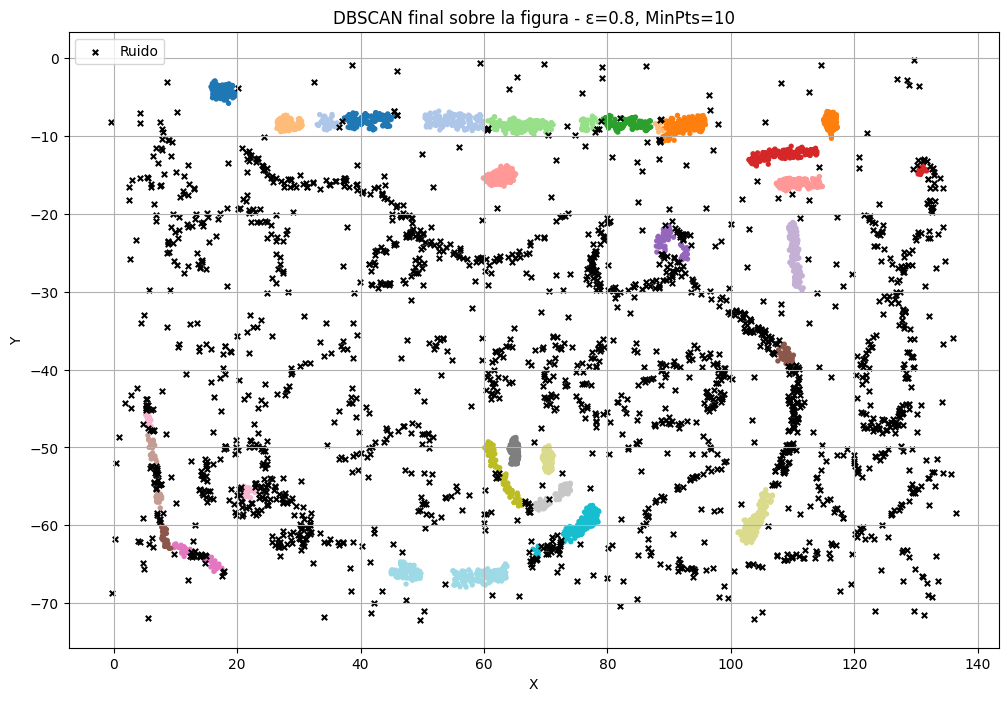

In [17]:
plt.figure(figsize=(12, 8))

mask_clusters = etiquetas_finales != -1

plt.scatter(
    datos[mask_clusters, 0],
    datos[mask_clusters, 1],
    c=etiquetas_finales[mask_clusters],
    s=8,
    cmap="tab20"
)

mask_ruido = etiquetas_finales == -1

plt.scatter(
    datos[mask_ruido, 0],
    datos[mask_ruido, 1],
    s=15,
    marker="x",
    c="black",
    label="Ruido"
)

plt.title(f"DBSCAN final sobre la figura - ε={eps_final}, MinPts={minpts_final}")
plt.xlabel("X")
plt.ylabel("Y")
plt.legend()
plt.grid(True)
plt.show()

## 8. Evaluación del clustering

Se seleccionaron dos métricas de evaluación de desempeño para clustering, siguiendo la guía de la documentación de scikit-learn (`sklearn.metrics` y la sección *Clustering performance evaluation*):

- **Silhouette Score:** métrica *no supervisada* (no requiere etiquetas verdaderas). Evalúa qué tan bien separados están los clusters comparando la cohesión intra-cluster con la separación inter-cluster. Va de -1 a 1; valores cercanos a 1 indican clusters bien definidos.
- **Adjusted Rand Index (ARI):** métrica *supervisada*. Compara las etiquetas obtenidas por DBSCAN contra las etiquetas de referencia (a qué trazo de la figura pertenece cada punto originalmente), corrigiendo por el azar. Va de -1 a 1; 1 indica coincidencia perfecta.

Ambas métricas se calculan excluyendo los puntos etiquetados como ruido, ya que el ruido no pertenece a ningún cluster.

In [18]:
mask_metricas = etiquetas_finales != -1

datos_metricas = datos[mask_metricas]
etiquetas_metricas = etiquetas_finales[mask_metricas]
referencia_metricas = etiquetas_referencia[mask_metricas]

silhouette = silhouette_score(datos_metricas, etiquetas_metricas)
ari = adjusted_rand_score(referencia_metricas, etiquetas_metricas)

print("Métricas finales")
print("----------------")
print("Silhouette Score:", round(silhouette, 4))
print("Adjusted Rand Index (ARI):", round(ari, 4))

Métricas finales
----------------
Silhouette Score: 0.6623
Adjusted Rand Index (ARI): 0.9374


In [19]:
print("======================================")
print("       RESULTADOS FINALES DBSCAN")
print("======================================")
print(f"Epsilon (eps): {eps_final}")
print(f"MinPts: {minpts_final}")
print(f"Grupos originales en la figura: {len(etiquetas_validas)}")
print(f"Clusters encontrados: {num_clusters}")
print(f"Puntos considerados ruido: {num_ruido} ({num_ruido/len(datos)*100:.1f}%)")
print(f"Silhouette Score: {silhouette:.4f}")
print(f"Adjusted Rand Index (ARI): {ari:.4f}")

       RESULTADOS FINALES DBSCAN
Epsilon (eps): 0.8
MinPts: 10
Grupos originales en la figura: 28
Clusters encontrados: 37
Puntos considerados ruido: 1835 (33.7%)
Silhouette Score: 0.6623
Adjusted Rand Index (ARI): 0.9374


### Comparación de configuraciones

Se probaron distintas combinaciones de ε y MinPts alrededor del codo detectado en la sección 6, usando la misma implementación de DBSCAN, para justificar la elección final.

In [20]:
configuraciones = [
    (0.7, 8),
    (0.7, 10),
    (0.75, 10),
    (0.8, 10),
    (0.8, 12),
]

filas_tabla = []

for eps_prueba, minpts_prueba in configuraciones:

    etiquetas_prueba = dbscan(datos, eps_prueba, minpts_prueba)

    n_clusters_prueba = len(set(etiquetas_prueba) - {-1})
    n_ruido_prueba = np.sum(etiquetas_prueba == -1)

    mask_prueba = etiquetas_prueba != -1

    sil_prueba = silhouette_score(datos[mask_prueba], etiquetas_prueba[mask_prueba])
    ari_prueba = adjusted_rand_score(etiquetas_referencia[mask_prueba], etiquetas_prueba[mask_prueba])

    filas_tabla.append((eps_prueba, minpts_prueba, n_clusters_prueba, n_ruido_prueba, sil_prueba, ari_prueba))

print(f"{'eps':>6} {'MinPts':>8} {'Clusters':>10} {'Ruido':>8} {'Silhouette':>12} {'ARI':>8}")
for fila in filas_tabla:
    marca = " <-- seleccionada" if (fila[0] == eps_final and fila[1] == minpts_final) else ""
    print(f"{fila[0]:>6} {fila[1]:>8} {fila[2]:>10} {fila[3]:>8} {fila[4]:>12.4f} {fila[5]:>8.4f}{marca}")

   eps   MinPts   Clusters    Ruido   Silhouette      ARI
   0.7        8         51     1782       0.6371   0.9032
   0.7       10         39     1993       0.6668   0.9203
  0.75       10         39     1904       0.6727   0.9311
   0.8       10         37     1835       0.6623   0.9374 <-- seleccionada
   0.8       12         36     1959       0.6741   0.9235


## 9. Conclusiones

1. Se construyó un conjunto de datos sintético bidimensional **a partir de una figura propia**, dibujada a mano, de la cual se detectaron automáticamente (mediante binarización, dilatación morfológica y etiquetado de componentes conectadas) más de 20 grupos con formas irregulares y no convexas. Además, se generaron outliers distribuidos uniformemente sobre el área de la figura.

2. Se realizó un análisis de k-distancia con distintos valores de k para orientar la selección de ε y MinPts, identificando el codo característico de la curva alrededor de una distancia de 0.7 - 0.9.

3. Se implementó el algoritmo DBSCAN desde cero (sin usar `sklearn.cluster.DBSCAN`), y se evaluaron varias combinaciones de ε y MinPts. Se seleccionó la configuración **ε = 0.8, MinPts = 10** por ofrecer el mejor balance entre número de clusters, proporción de ruido y las métricas de evaluación.

4. El número de clusters encontrados por DBSCAN es mayor al número de trazos originales de la figura. Esto es esperable: al tratarse de trazos delgados y curvos (a diferencia de manchas compactas), algunas zonas del mismo trazo (por ejemplo, curvas cerradas o cruces) generan sub-regiones de densidad distinta, por lo que DBSCAN los reconoce como clusters separados. Este resultado ilustra una limitación conocida de DBSCAN frente a clusters muy elongados o de densidad variable.

5. A pesar de esta fragmentación, el **Adjusted Rand Index** obtenido es alto, lo cual indica que, aun cuando DBSCAN subdivide algunos trazos, la asignación de puntos sigue siendo mayormente coherente con la estructura original de la figura. El **Silhouette Score** confirma además que los clusters encontrados están razonablemente bien separados entre sí.
